# Paragraph and answers: time on the text against time on the answers

In Study 1, 360 participants read a paragraph and then answered a multiple-choice question about it (19,436 trials). Each paragraph has three parts: the **critical** part, which holds the answer, the **distractor** part, which supports a wrong answer, and the rest (**outside**). This analysis asks whether the time a participant spends on each part of the paragraph goes together with the time they then spend on each of the four answers and on the question. It reads Study 1's trial table (`data/datasets/l1_onestop/features/model_ready.csv`, one row per trial) and the same table for each group, hunters and gatherers. The result is a correlation map: the three paragraph parts as rows, the four answers and the question as columns, for two reading-time measures (RT and TFD) and for dwell proportions. Each cell is tested with the participant as the unit -- a correlation within each participant, and a test of the 360 values against 0 -- because one person's ~54 trials are not independent, and a test over all 19k trials would call almost any correlation significant. Participants also read the same texts, and that nesting is not modelled. Correlations are Spearman throughout, because reading times are strongly skewed.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

from src.config import columns as C
from src.analyses.text_qa_relationship import (
    answer_cols, region_cols, pretty_labels,
    load_all_participants_features, load_group_features,
    metric_map_stats, group_map_stats, summarise_map, shared_vmax,
    plot_pooled_maps, plot_maps, plot_contrasts,
    reference_contrasts, region_contrasts, group_contrast,
    bootstrap_maps, plot_bootstrap_maps,
    load_all_proportion_features, load_group_proportion_features,
    proportion_summary, proportion_map_stats, group_proportion_map_stats,
    plot_proportion_maps,
)

# The saved trial tables, read as they are (rebuild=False is the default).
df = load_all_participants_features()
group_dfs = load_group_features()   # {"hunters": ..., "gatherers": ...}

all: (19436, 219)
hunters: (9719, 219)
gatherers: (9717, 219)


## The input: one row per trial

A map uses eight columns of the trial table: the time on each of the three paragraph parts, and the time on each of the five areas of the answer screen. `RT_normalized_*` is the time spent on visits to the area, divided by its number of words; `TFD_normalized_*` is the summed duration of the fixations on it, also per word. An area nobody looked at has 0. **Answer A is always the correct answer**; B is a misreading of the critical part, C is built on the distractor part, and D has no support in the text.

In [2]:
print(f"{len(df):,} trials, {df[C.PARTICIPANT_ID].nunique()} participants;",
      {name: f"{len(g):,} trials" for name, g in group_dfs.items()})
df[[C.PARTICIPANT_ID, *region_cols("RT"), *answer_cols("RT")]].head().round(2)

19,436 trials, 360 participants; {'hunters': '9,719 trials', 'gatherers': '9,717 trials'}


,participant_id,RT_normalized_distractor,RT_normalized_critical,RT_normalized_outside,RT_normalized_answer_A,RT_normalized_answer_B,RT_normalized_answer_C,RT_normalized_answer_D,RT_normalized_question
0,l42_2070,110.50,256.87,123.25,322.12,213.86,180.43,250.71,54.50
1,l42_2070,300.67,284.60,125.97,113.00,270.56,180.00,131.80,30.33
2,l42_2070,123.60,145.82,266.72,261.12,122.00,201.11,148.25,15.23
3,l42_2070,297.93,174.57,297.83,261.40,172.80,52.10,137.00,31.83
4,l42_2070,0.00,141.56,96.48,104.09,189.33,117.88,67.92,37.71


## The plain view: one correlation over all trials

`plot_pooled_maps` correlates the columns over all 19k trials at once, on a fixed scale from -1 to 1, with no tests. This mixes two things: whether a person who spends longer on a part of the paragraph also spends longer on an answer, and whether some people are simply slow everywhere. It is here for orientation only; the tests come next. `method="pearson"` gives the Pearson version.

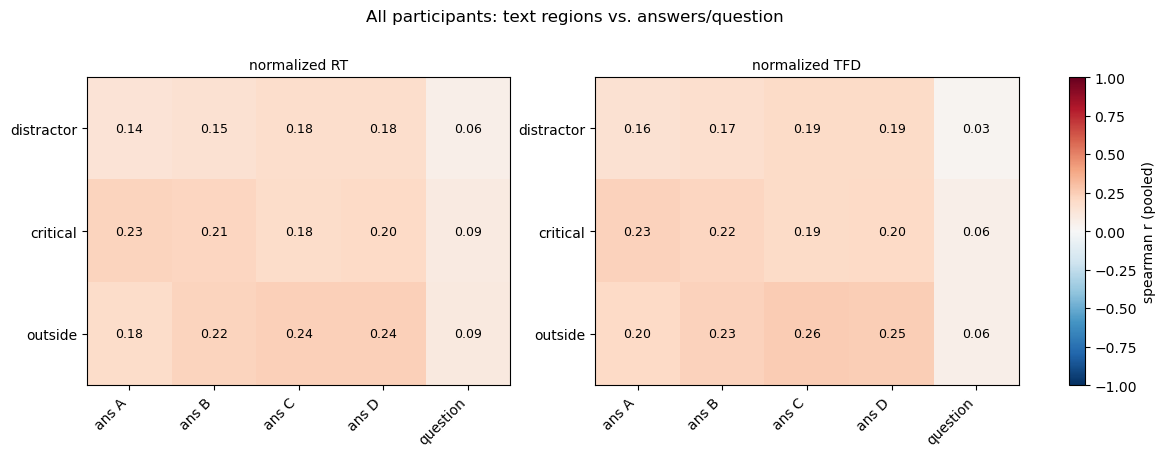

In [3]:
plot_pooled_maps(df, "All participants", save=False);

## The tested map: correlation within each participant

`metric_map_stats` computes each cell's correlation separately for every participant, turns it into a Fisher z, and tests the 360 values against 0 with a one-sample t-test. The p-values are corrected over the 15 cells of a map (Benjamini-Hochberg). Each cell shows the average within-participant r with its 95% interval and stars; hatched grey cells are not significant after the correction. The colour scale runs only to the largest |r| in the figure, so the colours cannot be compared with the plain view above.

In the table, `r` is the within-participant correlation and `r_pooled` the plain one from above; `d` is the effect size (mean z over its SD), and `n` the number of participants in the cell. The table is for normalized RT; `summarise_map(stats_all["TFD"])` gives TFD. `scaling="pure"` uses the times not divided by word count, and `adjust=None` or `adjust="holm"` changes the correction.

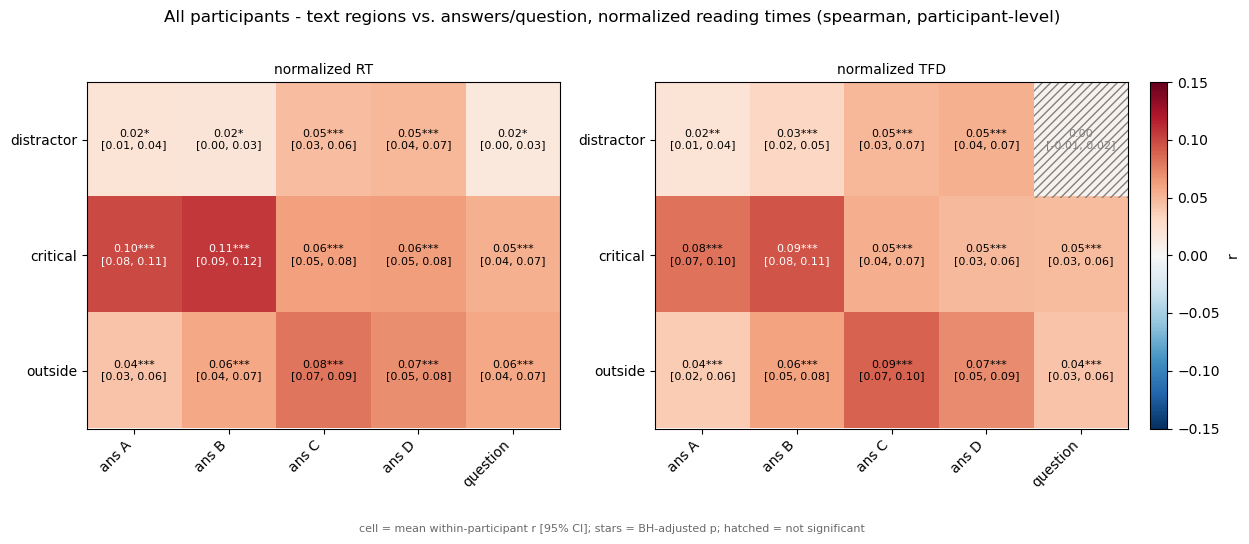

In [4]:
stats_all = metric_map_stats(df)          # {"RT": ..., "TFD": ...}
plot_maps(stats_all, "All participants", show_ci=True, save=False);

In [5]:
summarise_map(stats_all["RT"]).round(3)   # normalized RT, one row per cell, most significant first

,row,col,n,r,ci_low,ci_high,d,t,p,p_adj,stars,r_pooled
0,critical,ans B,360,0.106,0.091,0.121,0.724,13.741,0.000,0.000,***,0.213
1,critical,ans A,360,0.099,0.084,0.114,0.692,13.129,0.000,0.000,***,0.226
2,outside,ans C,360,0.080,0.065,0.094,0.561,10.642,0.000,0.000,***,0.241
3,outside,ans D,360,0.070,0.054,0.085,0.467,8.859,0.000,0.000,***,0.237
4,critical,ans C,360,0.062,0.047,0.076,0.442,8.377,0.000,0.000,***,0.182
5,critical,ans D,360,0.063,0.048,0.078,0.425,8.067,0.000,0.000,***,0.200
6,outside,ans B,360,0.058,0.044,0.073,0.405,7.688,0.000,0.000,***,0.220
7,outside,question,360,0.058,0.043,0.074,0.384,7.280,0.000,0.000,***,0.094
8,critical,question,360,0.053,0.037,0.069,0.351,6.668,0.000,0.000,***,0.086
9,distractor,ans D,360,0.050,0.035,0.066,0.342,6.495,0.000,0.000,***,0.177


## Comparing cells: is one correlation stronger than another?

Two cells of a map are measured on the same participants, so they are compared with a paired t-test on each participant's difference in z. `reference_contrasts` takes one cell -- here critical part ~ answer A -- and compares it with every other cell in its row. A positive difference means that critical ~ answer A is the stronger correlation. A filled marker survives the correction over these four tests; a hollow one does not. The intervals are in Fisher z and are not corrected, so a hollow marker whose interval just clears 0 is the correction at work, not a contradiction.

Passing several sets of stats, e.g. `{"all": stats_all, **stats_by_group}`, runs the same comparisons for each group. The table below is `region_contrasts`: the three paragraph parts compared with each other within each column, corrected over those 15 tests. `compare_cells` takes any pairs of cells you name (built with `map_cell`).

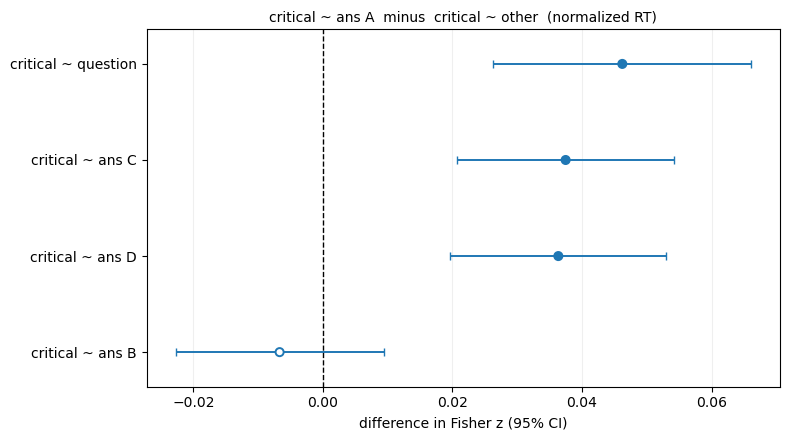

In [6]:
crit_vs_rest = reference_contrasts({"all participants": stats_all}, region="critical", answer="answer_A", metric="RT")
plot_contrasts(crit_vs_rest, title="critical ~ ans A  minus  critical ~ other  (normalized RT)",
               xlabel="difference in Fisher z (95% CI)", save=False);

In [7]:
rc = region_contrasts(stats_all, "RT")   # the three parts compared pairwise within each column: 15 paired tests
rc.assign(cell_a=pretty_labels(rc["cell_a"]), cell_b=pretty_labels(rc["cell_b"])).round(3)

,cell_a,cell_b,n,r_a,r_b,delta_r,delta_z,ci_low,ci_high,t,p,d,p_adj,sig,stars
0,distractor ~ ans B,critical ~ ans B,360,0.020,0.106,-0.086,-0.086,-0.106,-0.067,-8.568,0.000,-0.452,0.000,True,***
1,distractor ~ ans A,critical ~ ans A,360,0.020,0.099,-0.079,-0.079,-0.099,-0.060,-7.917,0.000,-0.417,0.000,True,***
2,critical ~ ans A,outside ~ ans A,360,0.099,0.043,0.056,0.056,0.036,0.077,5.550,0.000,0.293,0.000,True,***
3,critical ~ ans B,outside ~ ans B,360,0.106,0.058,0.047,0.047,0.029,0.066,4.973,0.000,0.262,0.000,True,***
4,distractor ~ question,outside ~ question,360,0.016,0.058,-0.043,-0.043,-0.061,-0.025,-4.654,0.000,-0.245,0.000,True,***
5,distractor ~ ans B,outside ~ ans B,360,0.020,0.058,-0.039,-0.039,-0.056,-0.022,-4.450,0.000,-0.235,0.000,True,***
6,distractor ~ ans C,outside ~ ans C,360,0.046,0.080,-0.034,-0.034,-0.050,-0.018,-4.098,0.000,-0.216,0.000,True,***
7,distractor ~ question,critical ~ question,360,0.016,0.053,-0.037,-0.037,-0.058,-0.017,-3.568,0.000,-0.188,0.001,True,***
8,distractor ~ ans A,outside ~ ans A,360,0.020,0.043,-0.023,-0.023,-0.041,-0.005,-2.506,0.013,-0.132,0.021,True,*
9,distractor ~ ans D,outside ~ ans D,360,0.050,0.070,-0.019,-0.019,-0.036,-0.002,-2.239,0.026,-0.118,0.039,True,*


## Hunters and gatherers

Hunters saw the question before reading the paragraph; gatherers saw it only afterwards. Each participant is in one group only (180 each), so the maps are computed for each group in the same way, and each cell is compared between the groups with a two-sample (Welch) t-test on the participants' z values. The two maps below share one colour scale. Each group has half the participants, so its intervals are wider; whether a cell differs between the groups is the test in the forest plot, not a comparison of the two maps by eye.

The forest plot shows hunters minus gatherers for all 15 cells of the normalized RT map, corrected together; filled markers survive the correction. The table has the same numbers, most significant first. `group_contrast(..., region="critical")` limits it to one row, which makes those 5 cells the correction family -- appropriate only when that row is the question you started with.

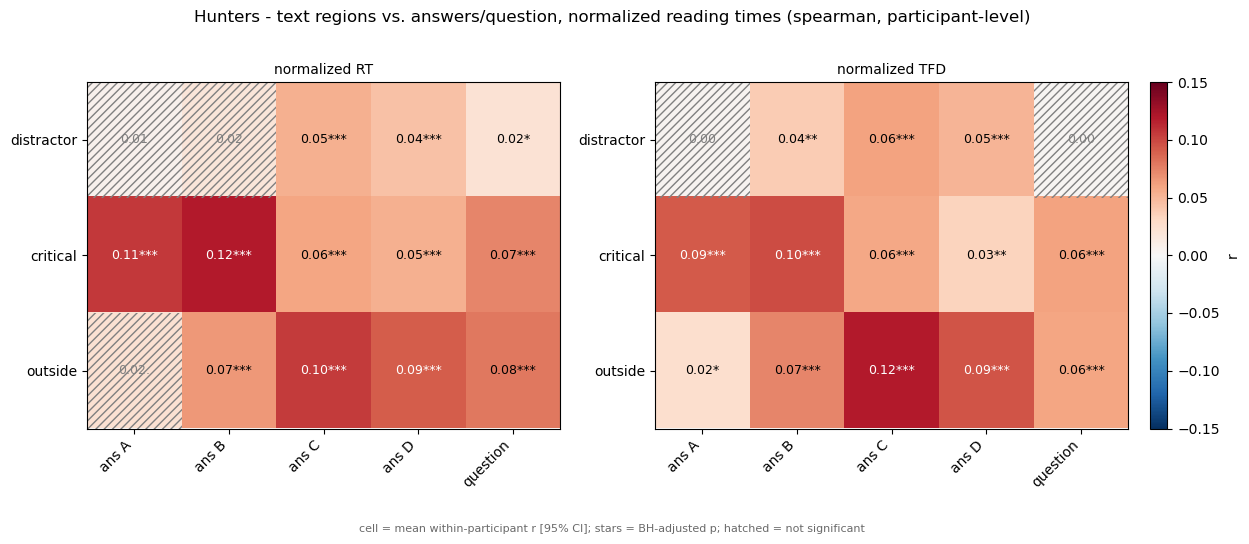

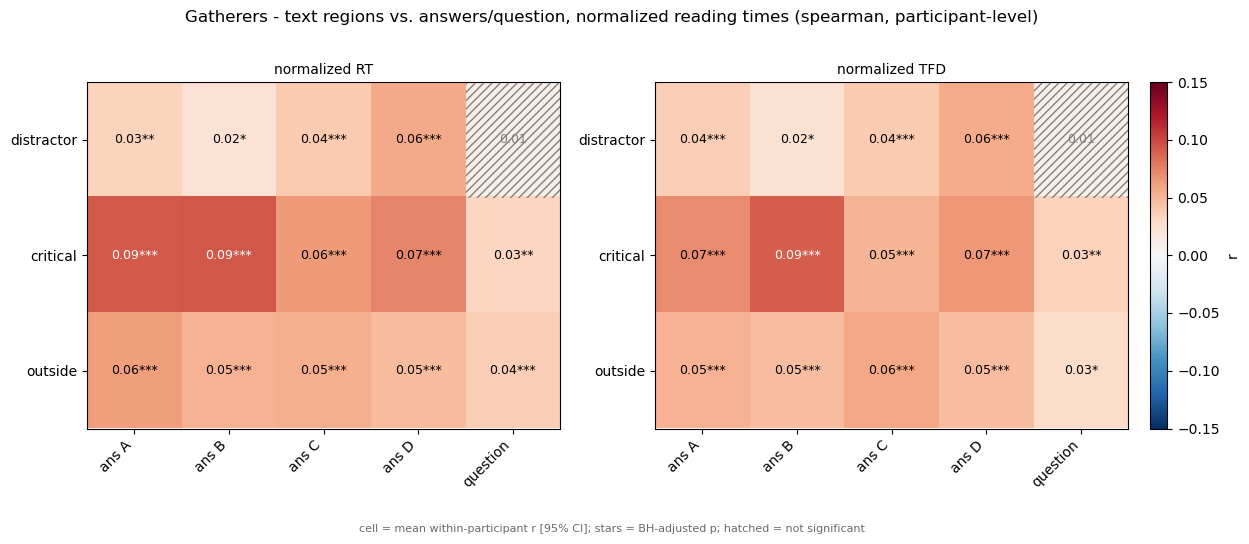

In [8]:
stats_by_group = group_map_stats(group_dfs)
vmax = shared_vmax(stats_by_group)        # one colour scale for both groups
for name, st in stats_by_group.items():
    plot_maps(st, name.capitalize(), vmax=vmax, save=False)

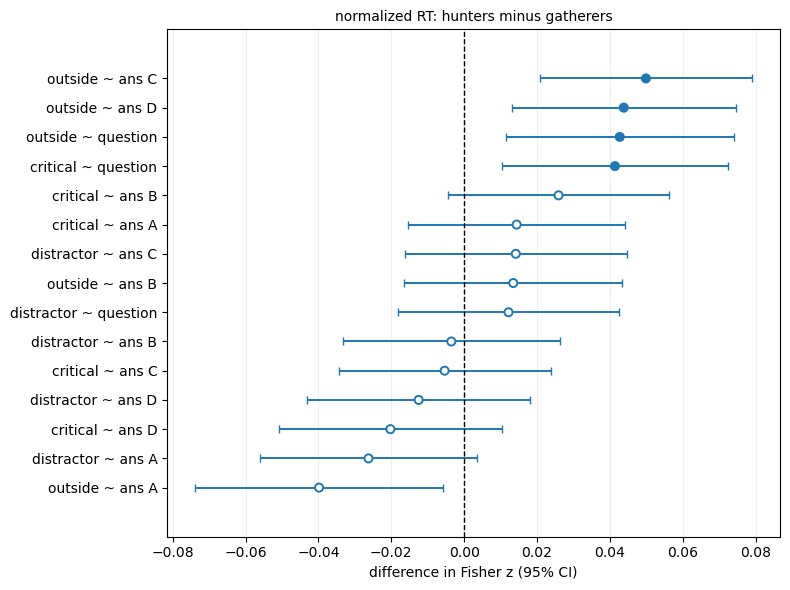

,row,col,n_hunters,n_gatherers,r_hunters,r_gatherers,delta_r,delta_z,ci_low,ci_high,t,p,d,p_adj,sig,stars
12,outside,ans C,180,180,0.105,0.055,0.050,0.050,0.021,0.079,3.365,0.001,0.355,0.013,True,*
14,outside,question,180,180,0.080,0.037,0.043,0.043,0.011,0.074,2.682,0.008,0.283,0.035,True,*
9,critical,question,180,180,0.074,0.032,0.041,0.041,0.010,0.072,2.618,0.009,0.276,0.035,True,*
13,outside,ans D,180,180,0.091,0.048,0.044,0.044,0.013,0.074,2.807,0.005,0.296,0.035,True,*
10,outside,ans A,180,180,0.023,0.063,-0.040,-0.040,-0.074,-0.006,-2.300,0.022,-0.242,0.066,False,.
0,distractor,ans A,180,180,0.007,0.033,-0.026,-0.026,-0.056,0.004,-1.729,0.085,-0.182,0.200,False,
6,critical,ans B,180,180,0.118,0.093,0.026,0.026,-0.004,0.056,1.682,0.093,0.177,0.200,False,
8,critical,ans D,180,180,0.053,0.073,-0.020,-0.020,-0.051,0.010,-1.298,0.195,-0.137,0.366,False,
2,distractor,ans C,180,180,0.053,0.039,0.014,0.014,-0.016,0.045,0.916,0.360,0.097,0.498,False,
3,distractor,ans D,180,180,0.044,0.057,-0.012,-0.012,-0.043,0.018,-0.804,0.422,-0.085,0.498,False,


In [9]:
by_group = group_contrast(stats_by_group, "RT")   # hunters minus gatherers, per cell
plot_contrasts(by_group, title="normalized RT: hunters minus gatherers",
               xlabel="difference in Fisher z (95% CI)", figsize=(8, 6), save=False)
by_group.assign(row=pretty_labels(by_group["row"]), col=pretty_labels(by_group["col"])).sort_values("p_adj").round(3)

## Dwell proportions instead of reading times

Here each area is described by its share of its screen's looking time instead of its time per word: the three paragraph shares add up to 1, and so do the five answer-screen shares. The map and the tests are the same as above. Because each side adds up to 1, a larger share for one part means smaller shares for the others, so the cells along a row cannot all move the same way. Trials with no looking time on the answer screen (all five shares 0) are dropped when the table is loaded, since that is a missing screen rather than a reading pattern; the loader says how many.

The first table is a quick check on the shares themselves; the second lists the 8 strongest cells of the all-participants map. `proportion_region_contrasts` and `proportion_group_contrast` run the cell and group comparisons on this map.

In [10]:
prop_df = load_all_proportion_features()
prop_group_dfs = load_group_proportion_features()
proportion_summary(prop_df).round(3)

all: (19436, 219)
text dwell proportions: already present on the frame (19436 trials); not re-merging
dropping 9 trials with no answer-screen dwell
hunters: (9719, 219)
text dwell proportions: already present on the frame (9719 trials); not re-merging
dropping 5 trials with no answer-screen dwell
gatherers: (9717, 219)
text dwell proportions: already present on the frame (9717 trials); not re-merging
dropping 4 trials with no answer-screen dwell


,count,mean,std,min,50%,max
area_dwell_proportion__distractor,19427.0,0.124,0.106,0.0,0.095,0.853
area_dwell_proportion__critical,19427.0,0.339,0.167,0.0,0.314,1.000
area_dwell_proportion__outside,19427.0,0.537,0.188,0.0,0.548,1.000
area_dwell_proportion__answer_A,19427.0,0.323,0.142,0.0,0.313,1.000
area_dwell_proportion__answer_B,19427.0,0.233,0.118,0.0,0.221,1.000
area_dwell_proportion__answer_C,19427.0,0.209,0.109,0.0,0.199,1.000
area_dwell_proportion__answer_D,19427.0,0.184,0.095,0.0,0.174,1.000
area_dwell_proportion__question,19427.0,0.051,0.077,0.0,0.029,1.000


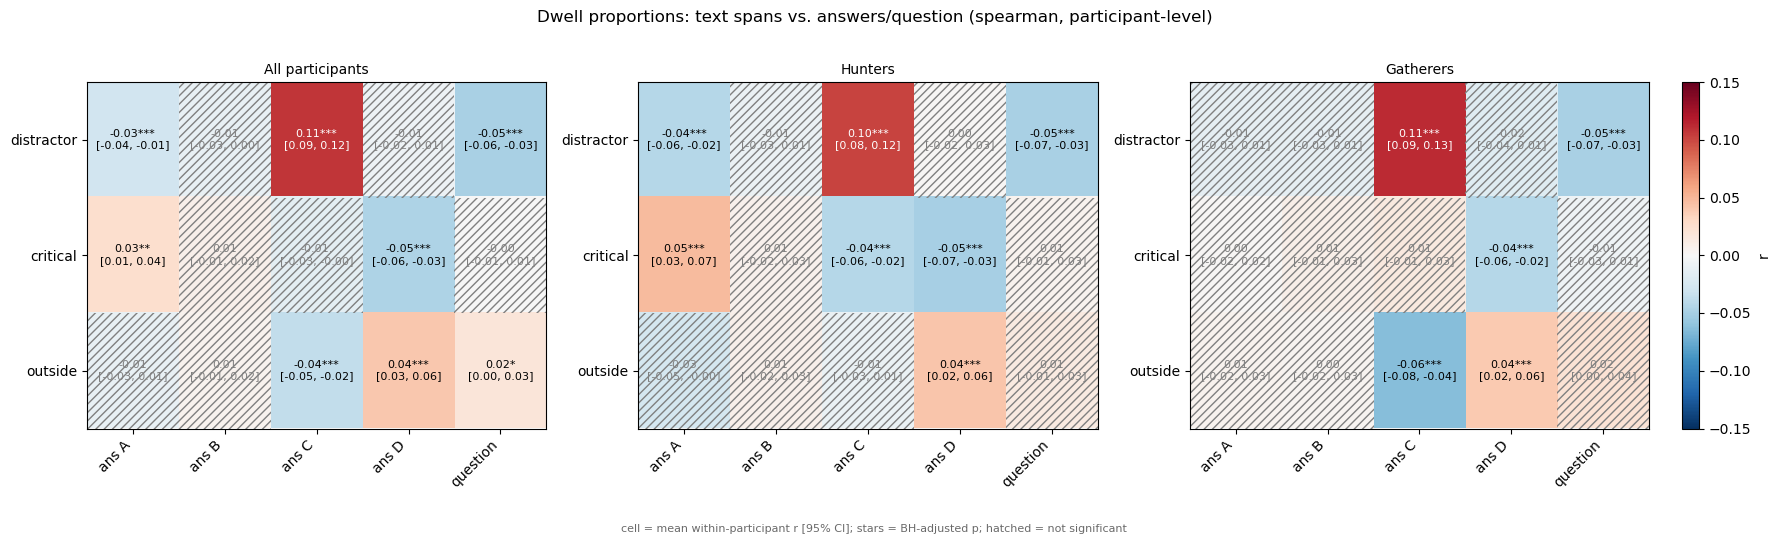

In [11]:
prop_all = proportion_map_stats(prop_df)
prop_by_group = group_proportion_map_stats(prop_group_dfs)
plot_proportion_maps({"All participants": prop_all,
                      "Hunters": prop_by_group["hunters"],
                      "Gatherers": prop_by_group["gatherers"]},
                     show_ci=True, save=False);

In [12]:
summarise_map(prop_all).round(3).head(8)

,row,col,n,r,ci_low,ci_high,d,t,p,p_adj,stars,r_pooled
0,distractor,ans C,360,0.107,0.093,0.121,0.770,14.609,0.000,0.000,***,0.109
1,distractor,question,360,-0.049,-0.063,-0.034,-0.341,-6.470,0.000,0.000,***,-0.049
2,critical,ans D,360,-0.046,-0.061,-0.032,-0.334,-6.329,0.000,0.000,***,-0.049
3,outside,ans D,360,0.041,0.026,0.056,0.287,5.443,0.000,0.000,***,0.044
4,outside,ans C,360,-0.037,-0.052,-0.022,-0.263,-4.985,0.000,0.000,***,-0.021
5,distractor,ans A,360,-0.028,-0.043,-0.013,-0.195,-3.707,0.000,0.001,***,-0.033
6,critical,ans A,360,0.025,0.010,0.040,0.176,3.336,0.001,0.002,**,0.053
7,outside,question,360,0.018,0.004,0.032,0.130,2.474,0.014,0.026,*,0.006


## Robustness: the plain correlation, with participants resampled

A check on the plain pooled correlation of the first map. It keeps that correlation over all trials as the estimate, and works out its interval by resampling whole participants (1,000 times, with replacement), so each person's trials stay together. This takes about 30 seconds. A bootstrap p-value cannot go below 1/1,000, so the strongest cells all get the same p and at most two stars; read the intervals rather than the stars. A cell that holds up both here and in the within-participant map does not depend on which of the two correlations is used.

`group_bootstrap_maps(group_dfs)` runs the same for each group; `n_boot` sets the number of resamples.

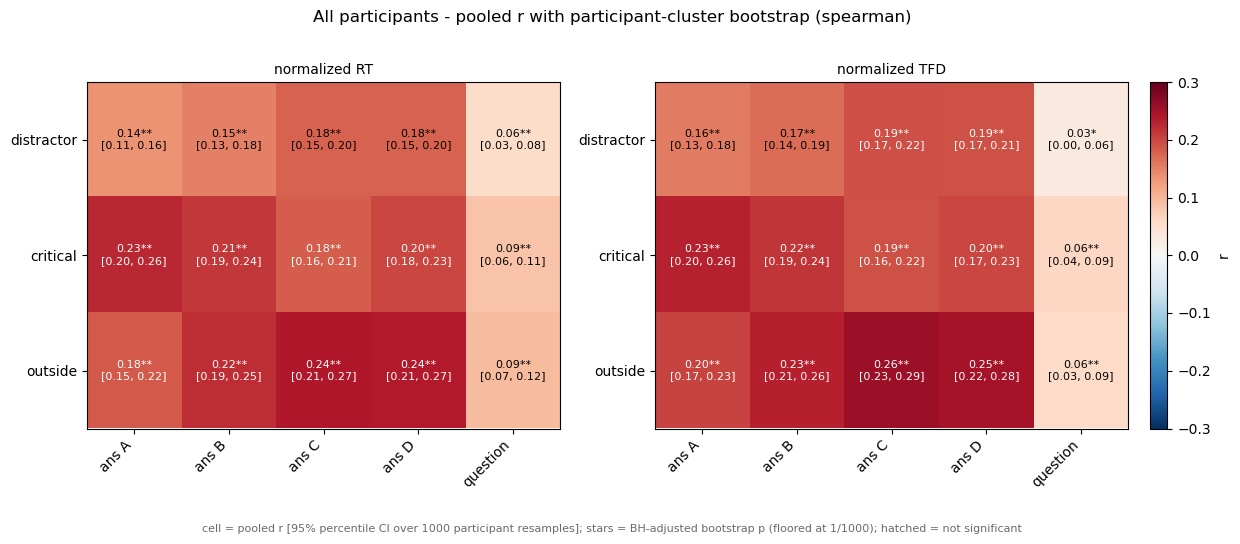

In [13]:
boot_all = bootstrap_maps(df, n_boot=1000)      # about 30 s
plot_bootstrap_maps(boot_all, "All participants", save=False);

In [14]:
summarise_map(boot_all["RT"]).round(3)

,row,col,n,r,ci_low,ci_high,p,p_adj,stars
0,distractor,ans A,360,0.135,0.108,0.164,0.001,0.001,**
1,distractor,ans B,360,0.150,0.126,0.176,0.001,0.001,**
2,distractor,ans C,360,0.177,0.152,0.202,0.001,0.001,**
3,distractor,ans D,360,0.177,0.152,0.201,0.001,0.001,**
4,distractor,question,360,0.055,0.033,0.079,0.001,0.001,**
5,critical,ans A,360,0.226,0.198,0.256,0.001,0.001,**
6,critical,ans B,360,0.213,0.189,0.238,0.001,0.001,**
7,critical,ans C,360,0.182,0.157,0.210,0.001,0.001,**
8,critical,ans D,360,0.200,0.175,0.229,0.001,0.001,**
9,critical,question,360,0.086,0.064,0.110,0.001,0.001,**
